In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.seasonal import seasonal_decompose


In [ ]:

np.random.seed(42)

dates = pd.date_range(
    start="2023-01-01",
    periods=36,
    freq="MS"
)

trend = np.arange(36) * 5
seasonality = 20 * np.sin(2 * np.pi * np.arange(36) / 12)
noise = np.random.randint(-10, 10, 36)

demand = 100 + trend + seasonality + noise

df = pd.DataFrame({
    "Date": dates,
    "Demand": demand.astype(int)
})

df.head()


,Date,Demand
0,2023-01-01,96
1,2023-02-01,124
2,2023-03-01,131
3,2023-04-01,135
4,2023-05-01,134


In [4]:

print(df)


         Date  Demand
0  2023-01-01      96
1  2023-02-01     124
2  2023-03-01     131
3  2023-04-01     135
4  2023-05-01     134
5  2023-06-01     131
6  2023-07-01     138
7  2023-08-01     125
8  2023-09-01     122
9  2023-10-01     118
10 2023-11-01     129
11 2023-12-01     137
12 2024-01-01     151
13 2024-02-01     176
14 2024-03-01     182
15 2024-04-01     186
16 2024-05-01     187
17 2024-06-01     196
18 2024-07-01     191
19 2024-08-01     191
20 2024-09-01     181
21 2024-10-01     190
22 2024-11-01     196
23 2024-12-01     208
24 2025-01-01     228
25 2025-02-01     236
26 2025-03-01     256
27 2025-04-01     247
28 2025-05-01     251
29 2025-06-01     263
30 2025-07-01     246
31 2025-08-01     243
32 2025-09-01     238
33 2025-10-01     252
34 2025-11-01     245
35 2025-12-01     268


In [5]:

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date")

df = df.set_index("Date")

print(df.isnull().sum())

print(df.head())


Demand    0
dtype: int64
            Demand
Date              
2023-01-01      96
2023-02-01     124
2023-03-01     131
2023-04-01     135
2023-05-01     134


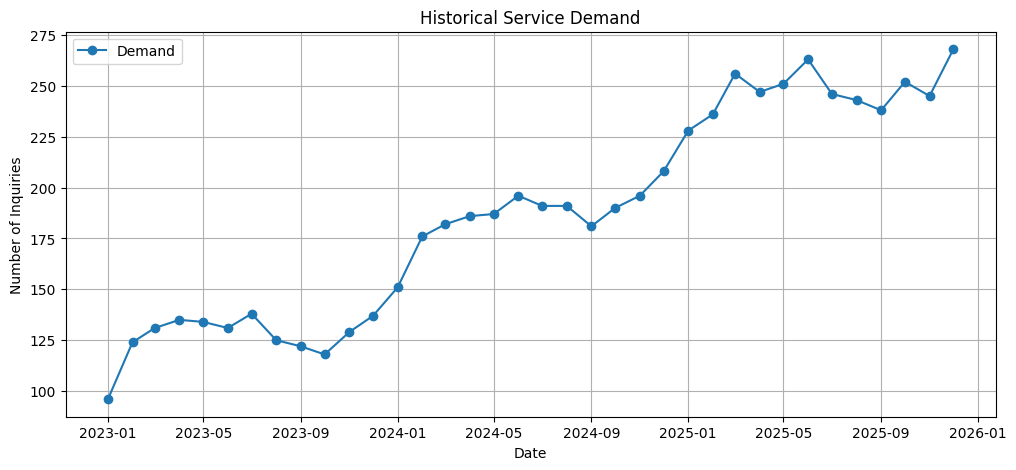

In [6]:

plt.figure(figsize=(12,5))

plt.plot(df.index, df["Demand"],
         marker="o", label="Demand")

plt.title("Historical Service Demand")
plt.xlabel("Date")
plt.ylabel("Number of Inquiries")

plt.legend()
plt.grid()
plt.show()


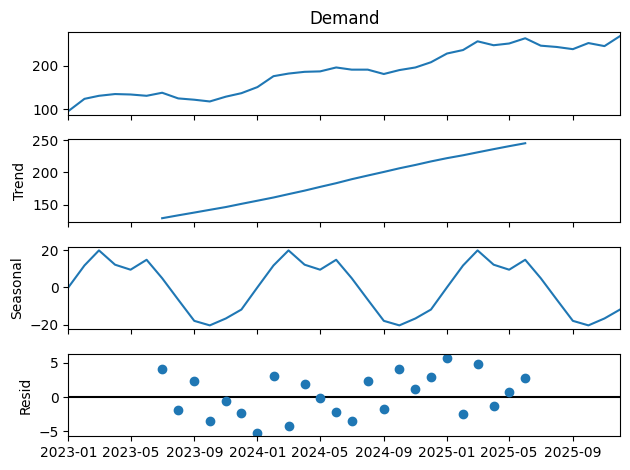

In [7]:

result = seasonal_decompose(
    df["Demand"],
    model="additive",
    period=12
)

result.plot()
plt.show()


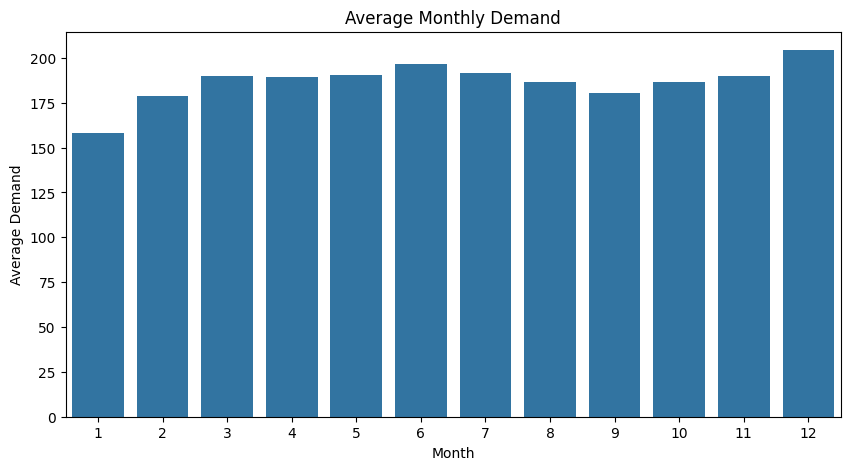

In [8]:

df["Month"] = df.index.month

monthly_demand = df.groupby("Month")["Demand"].mean()

plt.figure(figsize=(10,5))

sns.barplot(
    x=monthly_demand.index,
    y=monthly_demand.values
)

plt.title("Average Monthly Demand")
plt.xlabel("Month")
plt.ylabel("Average Demand")

plt.show()


In [9]:

df["Moving_Average"] = (
    df["Demand"].rolling(window=3).mean()
)

print(df[["Demand", "Moving_Average"]].tail(10))


            Demand  Moving_Average
Date                              
2025-03-01     256      240.000000
2025-04-01     247      246.333333
2025-05-01     251      251.333333
2025-06-01     263      253.666667
2025-07-01     246      253.333333
2025-08-01     243      250.666667
2025-09-01     238      242.333333
2025-10-01     252      244.333333
2025-11-01     245      245.000000
2025-12-01     268      255.000000


In [10]:

df["Lag_1"] = df["Demand"].shift(1)
df["Lag_2"] = df["Demand"].shift(2)
df["Lag_3"] = df["Demand"].shift(3)

df["Month_Number"] = df.index.month

df = df.dropna()

print(df.head())


            Demand  Month  Moving_Average  Lag_1  Lag_2  Lag_3  Month_Number
Date                                                                        
2023-04-01     135      4      130.000000  131.0  124.0   96.0             4
2023-05-01     134      5      133.333333  135.0  131.0  124.0             5
2023-06-01     131      6      133.333333  134.0  135.0  131.0             6
2023-07-01     138      7      134.333333  131.0  134.0  135.0             7
2023-08-01     125      8      131.333333  138.0  131.0  134.0             8


In [11]:

features = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Month_Number"
]

X = df[features]
y = df["Demand"]

# Last 6 months for testing
X_train = X.iloc[:-6]
X_test = X.iloc[-6:]

y_train = y.iloc[:-6]
y_test = y.iloc[-6:]

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Actual Demand:")
print(y_test.values)

print("Predicted Demand:")
print(predictions)


Actual Demand:
[246 243 238 252 245 268]
Predicted Demand:
[256.27 258.38 257.94 255.19 255.08 255.47]


In [12]:

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

print("MAE:", mae)
print("RMSE:", rmse)


MAE: 11.898333333333332
RMSE: 12.964080504738208


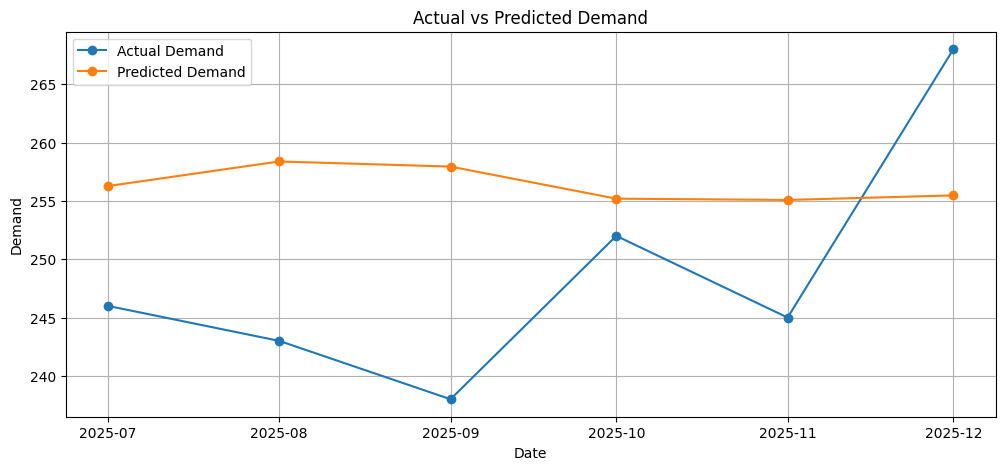

In [13]:

plt.figure(figsize=(12,5))

plt.plot(
    y_test.index,
    y_test.values,
    marker="o",
    label="Actual Demand"
)

plt.plot(
    y_test.index,
    predictions,
    marker="o",
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.grid()
plt.show()


In [14]:

history = df["Demand"].tolist()

future_predictions = []

for i in range(3):

    lag1 = history[-1]
    lag2 = history[-2]
    lag3 = history[-3]

    next_date = df.index[-1] + pd.DateOffset(
        months=i+1
    )

    month = next_date.month

    input_data = pd.DataFrame([[
        lag1, lag2, lag3, month
    ]], columns=features)

    forecast = model.predict(input_data)[0]

    future_predictions.append(forecast)

    history.append(forecast)

future_dates = pd.date_range(
    start=df.index[-1] + pd.DateOffset(months=1),
    periods=3,
    freq="MS"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Demand": future_predictions
})

print(forecast_df)


        Date  Predicted_Demand
0 2026-01-01            250.36
1 2026-02-01            250.43
2 2026-03-01            255.08


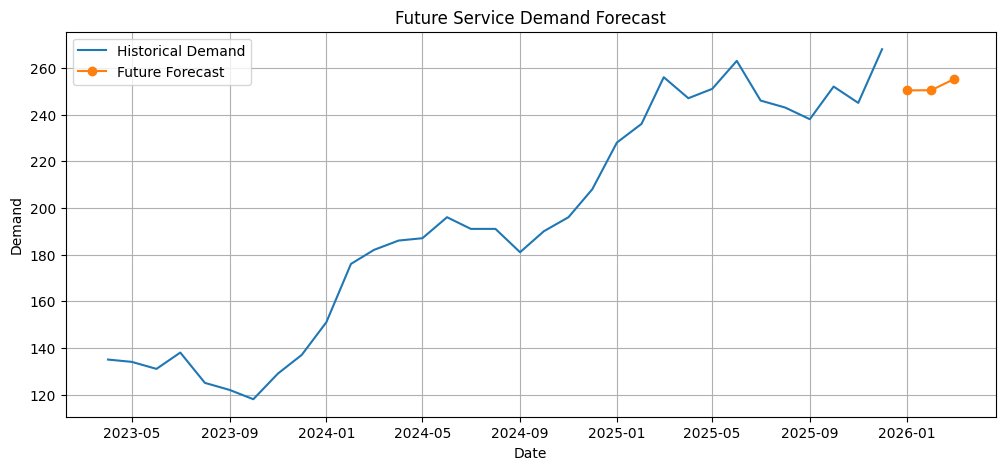

In [15]:

plt.figure(figsize=(12,5))

plt.plot(
    df.index,
    df["Demand"],
    label="Historical Demand"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_Demand"],
    marker="o",
    label="Future Forecast"
)

plt.title("Future Service Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.grid()
plt.show()


In [17]:

!pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 118.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 93.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [18]:

import streamlit as st

print("Streamlit installed successfully!")
print(st.__version__)


Streamlit installed successfully!
1.67.0


In [19]:
import streamlit as st
st.title("Sales & Service Demand Forecasting")

2026-11-14 12:21:30.775 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 12:21:30.940 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-14 12:21:30.940 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 12:21:30.941 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [21]:

!streamlit run app.py &>/content/logs.txt &
